In [1]:
import numpy as np
from collections import Counter

def entropi(data: bytes) -> float:
    """Entropi i bits per symbol (byte). Den teoretiske nedre grensen for lossless koding."""
    antall = Counter(data)            # hvor mange ganger hver byte forekommer
    n = len(data)
    p = np.array(list(antall.values())) / n   # andelen av hver byte
    return np.sum(-p * np.log2(p))                        # fyll inn formelen. Hint: np.sum og np.log2

data = b"ABRACADABRA"                 # b"..." er bytes, ikke tekst
print(entropi(data))                  # skal gi ca 2.04
print(entropi(data) * len(data))      # minste antall bits for hele ordet, ca 22.4

2.0403733936884962
22.44410733057346


In [2]:
with open("excel_compressor/insurance.csv", "rb") as f:    # "rb" = les som bytes
    csv = f.read()
print(len(csv), "bytes,", entropi(csv), "bits per byte")

55628 bytes, 4.531237018341825 bits per byte


In [3]:
#RLE

def rle_enkel(data: bytes) -> list:
    """Enkel RLE: returnerer en liste med (antall, byte)-par."""
    resultat = []
    i = 0
    while i < len(data):
        antall = 1
        # Tell hvor mange like bytes som følger etter data[i].
        while i + antall < len(data) and data[i + antall] == data[i]:
            antall += 1
        resultat.append((antall, data[i]))
        i += antall                # hopp forbi hele rekken du nettopp telte
    return resultat

print(rle_enkel(b"AAAAAABBBCCDAA"))   # forvent [(6, 65), (3, 66), (2, 67), (1, 68), (2, 65)]

[(6, 65), (3, 66), (2, 67), (1, 68), (2, 65)]


In [4]:
# skikkelig RLE: returnerer bytes, ikke (antall, byte)-par. Antall må være 1-255, ellers feiler det.
def rle_encode(data: bytes) -> bytes:
    """RLE til bytes: hvert run lagres som [antall][verdi], antall maks 255."""
    ut = bytearray()                  # bytearray kan utvides; gjøres om til bytes til slutt
    i = 0
    while i < len(data):
        antall = 1
        while i + antall < len(data) and data[i + antall] == data[i] and antall < 255:
            antall += 1
        ut.append(antall)             # første byte: antall
        ut.append(data[i])            # andre byte: verdien
        i += antall
    return bytes(ut)

def rle_decode(kode: bytes) -> bytes:
    """Motsatt vei: les par av [antall][verdi] og gjenta verdien."""
    ut = bytearray()
    for j in range(0, len(kode), 2):  # hopp 2 og 2: ett par om gangen
        antall, verdi = kode[j], kode[j + 1]
        ut.extend(bytes([verdi]) * antall)  # legg til verdien 'antall' ganger. Hint: bytes([verdi]) * antall
    return bytes(ut)

for navn, d in [("ABRACADABRA", b"ABRACADABRA"),
                ("1000 A", b"A" * 1000),
                ("insurance.csv", csv)]:
    k = rle_encode(d)
    print(f"{navn}: {len(d)} -> {len(k)} bytes ({len(k)/len(d):.0%})",
          "OK" if rle_decode(k) == d else "FEIL")

ABRACADABRA: 11 -> 22 bytes (200%) OK
1000 A: 1000 -> 8 bytes (1%) OK
insurance.csv: 55628 -> 108624 bytes (195%) OK


In [5]:
#Packbits

def packbits_encode(data: bytes) -> bytes:
    ut = bytearray()
    i = 0
    while i < len(data):
        # 1) Tell gjentakelse fra i (maks 128). Samme løkke som i rle_encode.
        run = 1
        while i + run < len(data) and data[i + run] == data[i] and run < 128:
            run += 1

        if run >= 3:
            # 2a) Gjentakelsesblokk: header = -(run-1), lagret som 256-(run-1)
            ut.append(256 - (run - 1))  # header = -(run-1) lagret som 256-(run-1)
            ut.append(data[i])
            i += run
        else:
            # 2b) Blokk med vanlige bytes: samle til vi treffer en 3-gjentakelse eller 128
            start = i
            while i < len(data) and i - start < 128:
                if i + 2 < len(data) and data[i] == data[i+1] == data[i+2]:
                    break                     # en gjentakelse starter her, avslutt blokken
                i += 1
            lengde = i - start
            ut.append(lengde - 1)                    # header = lengde - 1  (0–127)
            ut.extend(data[start:i])          # selve bytene, uendret
    return bytes(ut)

def packbits_decode(kode: bytes) -> bytes:
    ut = bytearray()
    j = 0
    while j < len(kode):
        h = kode[j]; j += 1
        if h < 128:                   # vanlige bytes: kopier h+1 bytes
            ut.extend(kode[j : j + h + 1])
            j += h + 1
        elif h > 128:                 # gjentakelse: 257 - h kopier av neste byte
            ut.extend(bytes([kode[j]]) * (257 - h))
            j += 1
        # h == 128 brukes ikke
    return bytes(ut)

for navn, d in [("ABRACADABRA", b"ABRACADABRA"),
                ("1000 A", b"A" * 1000),
                ("insurance.csv", csv)]:
    k = packbits_encode(d)
    print(f"{navn}: {len(d)} -> {len(k)} bytes ({len(k)/len(d):.0%})",
          "OK" if packbits_decode(k) == d else "FEIL")

ABRACADABRA: 11 -> 12 bytes (109%) OK
1000 A: 1000 -> 16 bytes (2%) OK
insurance.csv: 55628 -> 56028 bytes (101%) OK


In [6]:
#Huffman

import heapq
from collections import Counter

def bygg_huffman_tre(data: bytes):
    frekvens = Counter(data)
    # Hvert element i heapen: (frekvens, løpenummer, tre)
    # Løpenummeret skiller like frekvenser, så Python aldri må sammenligne to trær.
    heap = [(f, i, b) for i, (b, f) in enumerate(sorted(frekvens.items()))]
    heapq.heapify(heap)
    teller = len(heap)
    while len(heap) > 1:
        f1, _, venstre = heapq.heappop(heap)     # minste
        f2, _, hoyre = heapq.heappop(heap)       # nest minste
        heapq.heappush(heap, (f1 + f2, teller, (venstre, hoyre))) # ny node: summen av frekvensene, og paret (venstre, hoyre)
        teller += 1
    return heap[0][2]                            # roten

def lag_koder(tre, prefiks="", koder=None):
    """Gå gjennom treet: venstre = '0', høyre = '1'. Returnerer {byte: kode}."""
    if koder is None:                # NB: ikke koder={} i parameterlista. Se forklaringen under.
        koder = {}
    if isinstance(tre, int):         # blad: vi har kommet fram til en byte
        koder[tre] = prefiks or "0"  # spesialtilfelle: data med bare ett unikt symbol
    else:
        venstre, hoyre = tre
        lag_koder(venstre, prefiks + "0", koder)
        lag_koder(hoyre, prefiks + "1", koder)
    return koder


#test
tre = bygg_huffman_tre(b"ABRACADABRA")
koder = lag_koder(tre)
print({chr(k): v for k, v in koder.items()})              # vis som bokstaver
totalt = sum(len(koder[b]) for b in b"ABRACADABRA")
print(totalt, "bits")          # skal bli 23

# test for csv
with open("excel_compressor/insurance.csv", "rb") as f:
    csv = f.read()
tre = bygg_huffman_tre(csv)
koder = lag_koder(tre)
totalt = sum(len(koder[b]) for b in csv)
print(totalt, "bits,", totalt/len(csv), "bits per byte")    

{'A': '0', 'C': '100', 'D': '101', 'B': '110', 'R': '111'}
23 bits
254356 bits, 4.57244553102754 bits per byte


In [7]:

def huffman_encode(data: bytes) -> bytes:
    frekvens = Counter(data)
    koder = lag_koder(bygg_huffman_tre(frekvens))
    bits = "".join(koder[b] for b in data)

    padding = (8 - len(bits) % 8) % 8   # antall 0-er som trengs for at len(bits) går opp i 8. Hint: % 8
    bits += "0" * padding

    ut = bytearray()
    # Header: antall symboler (2 bytes), så [byte][frekvens på 4 bytes] for hvert symbol, så padding (1 byte)
    ut += len(frekvens).to_bytes(2, "big")
    for b, f in sorted(frekvens.items()):
        ut.append(b)
        ut += f.to_bytes(4, "big")
    ut.append(padding)

    # Data: 8 og 8 bits blir én byte
    ut += bytes(int(bits[i:i+8], 2) for i in range(0, len(bits), 8))
    return bytes(ut)

def huffman_decode(kode: bytes) -> bytes:
    # Les header
    n = int.from_bytes(kode[0:2], "big")
    pos, frekvens = 2, {}
    for _ in range(n):
        frekvens[kode[pos]] = int.from_bytes(kode[pos+1:pos+5], "big")
        pos += 5
    padding = kode[pos]; pos += 1

    tre = bygg_huffman_tre(frekvens)                    # samme tre som koderen
    bits = "".join(f"{byte:08b}" for byte in kode[pos:])  # bytes tilbake til '0'/'1'
    if padding:
        bits = bits[:-padding]                          # fjern utfyllingen
    if isinstance(tre, int):                            # spesialtilfelle: bare ett unikt symbol
        return bytes([tre]) * len(bits)

    # Gå i treet: 0 = venstre, 1 = høyre. Når du treffer et blad, skriv byten og start fra roten igjen.
    ut, node = bytearray(), tre
    for bit in bits:
        if bit == "0":
            node = node[0]  # gå til venstre barn
        else:
            node = node[1]  # gå til høyre barn
        if isinstance(node, int):
            ut.append(node)
            node = tre  # start fra roten igjen
    return bytes(ut)

tre = bygg_huffman_tre(b"ABRACADABRA")
koder = lag_koder(tre)
print({chr(k): v for k, v in koder.items()})              # vis som bokstaver
totalt = sum(len(koder[b]) for b in b"ABRACADABRA")
print(totalt, "bits")                                       # skal bli 23

#test for csv
with open("excel_compressor/insurance.csv", "rb") as f:
    csv = f.read()
kode = huffman_encode(csv)
print(len(csv), "bytes,", len(kode), "bytes,", len(kode)/len(csv), "bytes per byte")    

for navn, d in [("ABRACADABRA", b"ABRACADABRA"),
                ("1000 A", b"A" * 1000),
                ("insurance.csv", csv)]:
    k = huffman_encode(d)
    print(f"{navn}: {len(d)} -> {len(k)} bytes ({len(k)/len(d):.0%})",
          "OK" if huffman_decode(k) == d else "FEIL")


{'A': '0', 'C': '100', 'D': '101', 'B': '110', 'R': '111'}
23 bits
55628 bytes, 31973 bytes, 0.574764507082764 bytes per byte
ABRACADABRA: 11 -> 31 bytes (282%) OK
1000 A: 1000 -> 133 bytes (13%) OK
insurance.csv: 55628 -> 31973 bytes (57%) OK


In [8]:
#Arithmetic test
def aritmetisk_float(melding, sanns):
    """sanns: {symbol: (start, slutt)}. Returnerer lav og høy grense etter hele meldingen."""
    lav, hoy = 0.0, 1.0
    for s in melding:
        bredde = hoy - lav
        start, slutt = sanns[s]
        hoy = lav + bredde * slutt
        lav = lav + bredde * start
    return lav, hoy

sanns = {"A": (0.0, 0.5), "B": (0.5, 0.75), "C": (0.75, 1.0)}
print(aritmetisk_float("BAC", sanns))           # sjekk mot tabellen over

lang = "BAC" * 30                                # 90 symboler
lav, hoy = aritmetisk_float(lang, sanns)
print(lav, hoy, hoy - lav)

(0.59375, 0.625)
0.6129032258064516 0.6129032258064516 0.0


In [9]:
from collections import Counter
from bisect import bisect_right

BITS = 32
TOP  = (1 << BITS) - 1      # 2^32 - 1: "1" in integer space
HALF = 1 << (BITS - 1)      # 2^31:     "0.5"
Q1   = 1 << (BITS - 2)      # 2^30:     "0.25"
Q3   = 3 * Q1               #           "0.75"

def build_cumulative(freq):
    """Sorted symbols and cumulative frequencies. Symbol i owns [cum[i], cum[i+1])."""
    symbols = sorted(freq)                 # sorted so encoder and decoder agree (same as Huffman)
    cum = [0]
    for s in symbols:
        cum.append(cum[-1] + freq[s])
    return symbols, cum

def arithmetic_encode(data: bytes) -> bytes:
    freq = Counter(data)
    symbols, cum = build_cumulative(freq)
    total = cum[-1]
    index = {s: i for i, s in enumerate(symbols)}

    bits, pending = [], 0
    def emit(b):
        nonlocal pending                   # modify the variable in the enclosing function
        bits.append(b)
        bits.extend([1 - b] * pending)     # pay off deferred bits: the opposite of b
        pending = 0

    low, high = 0, TOP
    for byte in data:
        i = index[byte]
        width = high - low + 1
        high = low + width * cum[i + 1] // total - 1   # same narrowing as by hand, in integers
        low  = low + width * cum[i] // total
        while True:                                     # renormalise as long as possible
            if high < HALF:                             # whole interval in lower half
                emit(0)
            elif low >= HALF:                           # whole interval in upper half
                emit(1)
                low -= HALF; high -= HALF               # shift down so the interval stays in range
            elif low >= Q1 and high < Q3:               # straddles the middle: defer the decision
                pending += 1
                low -= Q1; high -= Q1
            else:
                break                                   # no bit is determined yet
            low = 2 * low                               # double the interval
            high = 2 * high + 1

    pending += 1                                        # flush: enough bits to point into the final interval
    emit(0 if low < Q1 else 1)

    padding = (8 - len(bits) % 8) % 8
    bits += [0] * padding
    out = bytearray(len(data).to_bytes(4, "big"))       # header: number of symbols in the message
    out += len(symbols).to_bytes(2, "big")
    for s in symbols:
        out.append(s); out += freq[s].to_bytes(4, "big")
    for j in range(0, len(bits), 8):                    # 8 bits become one byte
        v = 0
        for b in bits[j:j + 8]:
            v = (v << 1) | b
        out.append(v)
    return bytes(out)

def arithmetic_decode(code: bytes) -> bytes:
    n = int.from_bytes(code[0:4], "big")
    m = int.from_bytes(code[4:6], "big")
    pos, freq = 6, {}
    for _ in range(m):
        freq[code[pos]] = int.from_bytes(code[pos + 1:pos + 5], "big"); pos += 5
    symbols, cum = build_cumulative(freq)
    total = cum[-1]

    data_bits = code[pos:]
    nbits = len(data_bits) * 8
    def bit(k):                                         # bit number k in the data (0 past the end)
        return 0 if k >= nbits else (data_bits[k >> 3] >> (7 - (k & 7))) & 1

    value = 0
    for k in range(BITS):                               # read the first 32 bits
        value = (value << 1) | bit(k)
    k, low, high, out = BITS, 0, TOP, bytearray()

    for _ in range(n):
        width = high - low + 1
        target = ((value - low + 1) * total - 1) // width   # where in [0, total) does value fall?
        i = bisect_right(cum, target) - 1                   # which symbol owns that position
        out.append(symbols[i])
        high = low + width * cum[i + 1] // total - 1        # same narrowing as the encoder
        low  = low + width * cum[i] // total
        while True:                                         # same renormalisation, value follows
            if high < HALF:
                pass
            elif low >= HALF:
                low -= HALF; high -= HALF; value -= HALF
            elif low >= Q1 and high < Q3:
                low -= Q1; high -= Q1; value -= Q1
            else:
                break
            low = 2 * low; high = 2 * high + 1
            value = 2 * value + bit(k); k += 1              # shift in the next bit
    return bytes(out)


for navn, d in [("ABRACADABRA", b"ABRACADABRA"),
                ("1000 A", b"A" * 1000),
                ("insurance.csv", csv)]:
    k = arithmetic_encode(d)
    print(f"{navn}: {len(d)} -> {len(k)} bytes ({len(k)/len(d):.0%})",
          "OK" if arithmetic_decode(k) == d else "FEIL")


ABRACADABRA: 11 -> 34 bytes (309%) OK
1000 A: 1000 -> 12 bytes (1%) OK
insurance.csv: 55628 -> 31690 bytes (57%) OK


In [17]:



BITS = 32
TOP = (1 << BITS) - 1
HALF = 1 << (BITS - 1)
QUARTER = 1 << (BITS - 2)
THREE_QUARTERS = 3 * QUARTER


class ContextModel:
    """Adaptive probability for ONE binary decision. Starts at 50/50 (Laplace)."""
    def __init__(self):
        self.c0 = 1
        self.c1 = 1

    def update(self, bit, limit=1024):
        # TODO 1: increment the counter matching `bit`
        if bit == 0:
            self.c0 += 1
        else:
            self.c1 += 1
        # Aging: halve counts so the model keeps adapting if the pattern changes
        if self.c0 + self.c1 > limit:
            self.c0 = (self.c0 + 1) // 2
            self.c1 = (self.c1 + 1) // 2


def context_index(mode, pos, node):
    # "position": 8 contexts, one per bit position (Tarjei's approach)
    # "tree": node = 1 followed by the bits seen so far in this byte -> 1..255
    return pos if mode == "position" else node


def cabac_encode(data, mode="tree"):
    contexts = [ContextModel() for _ in range(256)]
    low, high, pending = 0, TOP, 0
    out_bits = []

    def emit(bit):
        nonlocal pending
        out_bits.append(bit)
        out_bits.extend([1 - bit] * pending)
        pending = 0

    for byte in data:
        node = 1
        for pos in range(8):
            bit = (byte >> (7 - pos)) & 1          # binarization, MSB first
            model = contexts[context_index(mode, pos, node)]
            width = high - low + 1
            split = low + width * model.c0 // (model.c0 + model.c1) - 1   # [low, split] = "0"
            if bit == 0:          # encoder knows the bit -> just pick the sub-interval
                high = split
            else:
                low = split + 1
            model.update(bit)
            # TODO 2: narrow the interval depending on bit
             
            
            # TODO 3: update the model (AFTER coding, so the decoder can mirror it)
            node = (node << 1) | bit
            while True:                              # same renormalization as before
                if high < HALF:
                    emit(0)
                elif low >= HALF:
                    emit(1); low -= HALF; high -= HALF
                elif low >= QUARTER and high < THREE_QUARTERS:
                    pending += 1; low -= QUARTER; high -= QUARTER
                else:
                    break
                low = 2 * low
                high = 2 * high + 1

    pending += 1
    emit(0 if low < QUARTER else 1)
    while len(out_bits) % 8:
        out_bits.append(0)
    payload = bytes(int("".join(map(str, out_bits[i:i+8])), 2) for i in range(0, len(out_bits), 8))
    return len(data).to_bytes(4, "big") + payload    # header: only the length!


def cabac_decode(code, mode="tree"):
    n = int.from_bytes(code[:4], "big")
    bits = ((b >> (7 - i)) & 1 for b in code[4:] for i in range(8))   # generator: one bit at a time
    def next_bit():
        return next(bits, 0)

    value = 0
    for _ in range(BITS):
        value = (value << 1) | next_bit()
    low, high = 0, TOP
    contexts = [ContextModel() for _ in range(256)]
    out = bytearray()

    for _ in range(n):
        node = 1
        for pos in range(8):
            model = contexts[context_index(mode, pos, node)]
            width = high - low + 1
            split = low + width * model.c0 // (model.c0 + model.c1) - 1
            # TODO 4: decide bit from value vs split, and narrow exactly like the encoder
            if value <= split:
                low = low
                high = split
                bit = 0
            else:
                low = split + 1
                high = high
                bit = 1
            # TODO 5: update the model
            model.update(bit)
                
            node = (node << 1) | bit
            while True:
                if high < HALF:
                    pass
                elif low >= HALF:
                    low -= HALF; high -= HALF; value -= HALF
                elif low >= QUARTER and high < THREE_QUARTERS:
                    low -= QUARTER; high -= QUARTER; value -= QUARTER
                else:
                    break
                low = 2 * low
                high = 2 * high + 1
                value = 2 * value + next_bit()
        out.append(node & 0xFF)                     # after 8 bits, node = 1xxxxxxxx
    return bytes(out)

for navn, d in [("BAC", b"BAC" ),
                ("ABRACADABRA", b"ABRACADABRA"),
                ("1000 A", b"A" * 1000),
                ("insurance.csv", csv)]:
    k = cabac_encode(d)
    print(f"{navn}: {len(d)} -> {len(k)} bytes ({len(k)/len(d):.0%})",
          "OK" if cabac_decode(k) == d else "FEIL")
    
for mode in ["position", "tree"]:
    print(f"--- {mode} ---")
    for name, d in [("BAC", b"BAC" ),
                    ("ABRACADABRA", b"ABRACADABRA"),
                    ("1000 A", b"A" * 1000),
                    ("insurance.csv", csv)]:
        k = cabac_encode(d, mode)
        print(f"{name}: {len(d)} -> {len(k)} bytes ({len(k)/len(d):.0%})",
              "OK" if cabac_decode(k, mode) == d else "FAIL")

BAC: 3 -> 7 bytes (233%) OK
ABRACADABRA: 11 -> 11 bytes (100%) OK
1000 A: 1000 -> 15 bytes (2%) OK
insurance.csv: 55628 -> 31614 bytes (57%) OK
--- position ---
BAC: 3 -> 7 bytes (233%) OK
ABRACADABRA: 11 -> 11 bytes (100%) OK
1000 A: 1000 -> 15 bytes (2%) OK
insurance.csv: 55628 -> 42777 bytes (77%) OK
--- tree ---
BAC: 3 -> 7 bytes (233%) OK
ABRACADABRA: 11 -> 11 bytes (100%) OK
1000 A: 1000 -> 15 bytes (2%) OK
insurance.csv: 55628 -> 31614 bytes (57%) OK


In [18]:
import time
import statistics

def time_function(func, data, repeats=3):
    """Run func(data) several times; return median seconds and the result."""
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        result = func(data)
        times.append(time.perf_counter() - start)
    return statistics.median(times), result


# Each coder: (encode function, decode function)
coders = {
    "Simple RLE": (rle_encode, rle_decode),
    "PackBits":   (packbits_encode, packbits_decode),
    "Huffman":    (huffman_encode, huffman_decode),
    "Arithmetic": (arithmetic_encode, arithmetic_decode),
    "CABAC":      (cabac_encode, cabac_decode),
}

data = csv
print(f"Input: {len(data)} bytes\n")
print(f"{'Coder':<12} {'Size':>8} {'Encode (s)':>11} {'Decode (s)':>11} {'Enc MB/s':>9}  Roundtrip")

for name, (encode, decode) in coders.items():
    enc_time, encoded = time_function(encode, data)
    dec_time, decoded = time_function(decode, encoded)
    mb_per_s = len(data) / enc_time / 1_000_000      # throughput: comparable across file sizes
    print(f"{name:<12} {len(encoded):>8} {enc_time:>11.4f} {dec_time:>11.4f} {mb_per_s:>9.2f}  "
          f"{'OK' if decoded == data else 'FAIL'}")

Input: 55628 bytes

Coder            Size  Encode (s)  Decode (s)  Enc MB/s  Roundtrip
Simple RLE     108624      0.0147      0.0105      3.80  OK
PackBits        56028      0.0083      0.0001      6.68  OK
Huffman         31973      0.0103      0.0224      5.38  OK
Arithmetic      31690      0.1099      0.1326      0.51  OK
CABAC           31614      0.3540      0.3569      0.16  OK


In [19]:
import tracemalloc

def peak_memory(func, data):
    """Return peak memory (bytes) allocated while running func(data), and the result."""
    tracemalloc.start()
    result = func(data)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak, result


print(f"Input: {len(data)} bytes ({len(data)/1e6:.3f} MB)\n")
print(f"{'Coder':<12} {'Enc peak MB':>12} {'Dec peak MB':>12} {'Enc peak / input':>17}")

for name, (encode, decode) in coders.items():
    enc_peak, encoded = peak_memory(encode, data)
    dec_peak, _ = peak_memory(decode, encoded)
    print(f"{name:<12} {enc_peak/1e6:>12.2f} {dec_peak/1e6:>12.2f} {enc_peak/len(data):>16.1f}x")

Input: 55628 bytes (0.056 MB)

Coder         Enc peak MB  Dec peak MB  Enc peak / input
Simple RLE           0.23         0.12              4.1x
PackBits             0.12         0.11              2.2x
Huffman              0.76         2.35             13.7x
Arithmetic           2.13         0.15             38.3x
CABAC                2.18         0.14             39.1x


Size: 0.06 MB
  Simple RLE   0.010 s
  PackBits     0.009 s
  Huffman      0.013 s
  Arithmetic   0.113 s
  CABAC        0.356 s
Size: 0.11 MB
  Simple RLE   0.020 s
  PackBits     0.016 s
  Huffman      0.022 s
  Arithmetic   0.218 s
  CABAC        0.784 s
Size: 0.22 MB
  Simple RLE   0.041 s
  PackBits     0.034 s
  Huffman      0.045 s
  Arithmetic   0.461 s
  CABAC        1.749 s
Size: 0.45 MB
  Simple RLE   0.081 s
  PackBits     0.066 s
  Huffman      0.089 s
  Arithmetic   0.909 s
  CABAC        2.946 s


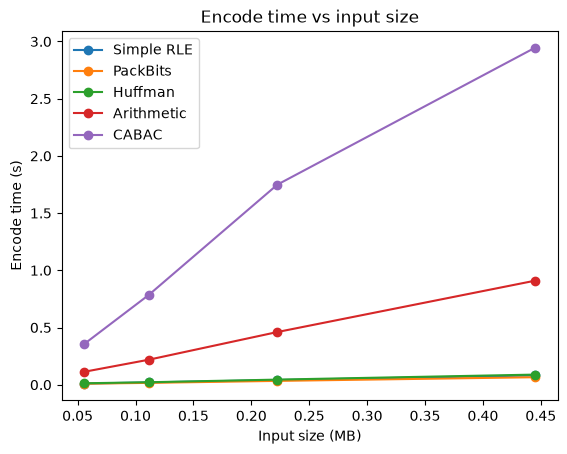

In [20]:
import matplotlib.pyplot as plt

factors = [1, 2, 4, 8]
results = {name: [] for name in coders}          # name -> list of encode times

for factor in factors:
    big = csv * factor                            # bytes * int repeats the content
    print(f"Size: {len(big)/1e6:.2f} MB")
    for name, (encode, decode) in coders.items():
        enc_time, _ = time_function(encode, big, repeats=1)   # 1 repeat: large inputs are slow
        results[name].append(enc_time)
        print(f"  {name:<12} {enc_time:.3f} s")

sizes_mb = [len(csv) * f / 1e6 for f in factors]
fig, ax = plt.subplots()
for name, times in results.items():
    ax.plot(sizes_mb, times, marker="o", label=name)
ax.set_xlabel("Input size (MB)")
ax.set_ylabel("Encode time (s)")
ax.set_title("Encode time vs input size")
ax.legend()
plt.show()

In [21]:

#Limit declaration and tessting:
REQ_MAX_SECONDS = 10      # K1: encode + decode of ~1 MB
REQ_MAX_MEM_FACTOR = 50   # K2: peak memory / input size

test_1mb = csv * 18       # 55 628 * 18 ≈ 1.0 MB
print(f"Test input: {len(test_1mb)/1e6:.2f} MB\n")
print(f"{'Coder':<12} {'Time (s)':>9} {'K1':>5} {'Mem factor':>11} {'K2':>5} {'K3':>5}")

for name, (encode, decode) in coders.items():
    enc_time, encoded = time_function(encode, test_1mb, repeats=1)
    dec_time, decoded = time_function(decode, encoded, repeats=1)
    total = enc_time + dec_time

    enc_peak, _ = peak_memory(encode, test_1mb)
    dec_peak, _ = peak_memory(decode, encoded)
    mem_factor = max(enc_peak, dec_peak) / len(test_1mb)   # worst of encode/decode

    k1 = "PASS" if total <= REQ_MAX_SECONDS else "FAIL"
    k2 = "PASS" if mem_factor <= REQ_MAX_MEM_FACTOR else "FAIL"
    k3 = "PASS" if decoded == test_1mb else "FAIL"
    print(f"{name:<12} {total:>9.2f} {k1:>5} {mem_factor:>10.1f}x {k2:>5} {k3:>5}")
    

Test input: 1.00 MB

Coder         Time (s)    K1  Mem factor    K2    K3
Simple RLE        0.39  PASS        4.0x  PASS  PASS
PackBits          0.15  PASS        2.1x  PASS  PASS
Huffman           0.63  PASS       41.8x  PASS  PASS
Arithmetic        4.33  PASS       40.3x  PASS  PASS
CABAC            13.04  FAIL       40.7x  PASS  PASS
